# **Data Fetching**

In [1]:
import os
import hashlib
import zipfile
import requests
from concurrent.futures import ThreadPoolExecutor

DATA_DIR = "/content/pad_ufes_20"
RAW_DIR = os.path.join(DATA_DIR, "_raw")
BASE = "https://data.mendeley.com/public-files/datasets/zr7vgbcyr2/files"

FILES = {
    "metadata.csv": ("fa850265-57da-48f0-ba3e-998b3e44b1f6", "14d145235cedb022548257acb0d84dcd949e2c916f65d2baa7c38ed5339e9527"),
    "imgs_part_1.zip": ("1cc2f71f-20a2-412d-b746-a9b9bc20c966", "0ab44f60938bf57445e12f518a8878954cc734e6b0aec6d01194e2d26b4b2dca"),
    "imgs_part_2.zip": ("559a60ed-5504-475d-996c-6a8bc253b5e7", "e2d9a3cbd58e823f5ae33163c48643e7d1b54ae3f9e145f01f8e9f16a363a60b"),
    "imgs_part_3.zip": ("34dcdf8e-e5f1-4b35-aa0b-5135051ff852", "ecc4ef10143a43e1d01cb736773148607a78b530417eb76f2c38ad24bf5d0d2c"),
}

os.makedirs(RAW_DIR, exist_ok=True)


def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def fetch(item):
    name, (file_id, expected) = item
    dest = os.path.join(RAW_DIR, name)
    if os.path.exists(dest) and sha256_of(dest) == expected:
        return name, "cached"
    url = f"{BASE}/{file_id}/file_downloaded"
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    if sha256_of(dest) != expected:
        os.remove(dest)
        raise RuntimeError(f"Checksum mismatch for {name}")
    return name, "downloaded"


with ThreadPoolExecutor(max_workers=4) as ex:
    for name, status in ex.map(fetch, FILES.items()):
        print(f"{name}: {status}")

os.replace(os.path.join(RAW_DIR, "metadata.csv"), os.path.join(DATA_DIR, "metadata.csv"))

for name in FILES:
    if name.endswith(".zip"):
        zpath = os.path.join(RAW_DIR, name)
        with zipfile.ZipFile(zpath) as z:
            z.extractall(DATA_DIR)
        os.remove(zpath)
        print(f"extracted {name}")

print("Dataset ready at:", DATA_DIR)


metadata.csv: downloaded
imgs_part_1.zip: downloaded
imgs_part_2.zip: downloaded
imgs_part_3.zip: downloaded
extracted imgs_part_1.zip
extracted imgs_part_2.zip
extracted imgs_part_3.zip
Dataset ready at: /content/pad_ufes_20


# **Dataset Exploration**

In [ ]:
import os
from collections import Counter

MAX_FILES_SHOWN = 5

print("Root:", DATA_DIR)
total_files = 0
ext_counter = Counter()

for root, dirs, files_ in sorted(os.walk(DATA_DIR)):
    dirs.sort()
    depth = os.path.relpath(root, DATA_DIR).count(os.sep) if root != DATA_DIR else 0
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/  ({len(files_)} files, {len(dirs)} subdirs)")
    for name in sorted(files_)[:MAX_FILES_SHOWN]:
        size_kb = os.path.getsize(os.path.join(root, name)) / 1024
        print(f"{indent}  - {name}  [{size_kb:.1f} KB]")
    if len(files_) > MAX_FILES_SHOWN:
        print(f"{indent}  ... and {len(files_) - MAX_FILES_SHOWN} more")
    total_files += len(files_)
    ext_counter.update(os.path.splitext(n)[1].lower() for n in files_)

print("\nTotal files:", total_files)
print("By extension:", dict(ext_counter))

csvs = [os.path.join(r, n) for r, _, fs in os.walk(DATA_DIR) for n in fs if n.lower().endswith(".csv")]
print("\nCSV files found:", csvs)


Root: /content/pad_ufes_20
pad_ufes_20/  (1 files, 4 subdirs)
  - metadata.csv  [308.8 KB]
_raw/  (0 files, 0 subdirs)
imgs_part_1/  (911 files, 0 subdirs)
  - PAT_100_393_595.png  [202.8 KB]
  - PAT_100_393_898.png  [75.4 KB]
  - PAT_101_1041_651.png  [1765.5 KB]
  - PAT_101_1041_658.png  [822.6 KB]
  - PAT_101_1041_898.png  [4882.7 KB]
  ... and 906 more
imgs_part_2/  (659 files, 0 subdirs)
  - PAT_1000_31_620.png  [420.6 KB]
  - PAT_1006_53_385.png  [104.6 KB]
  - PAT_1006_53_716.png  [69.9 KB]
  - PAT_1008_59_297.png  [1027.6 KB]
  - PAT_1013_82_876.png  [3898.2 KB]
  ... and 654 more
imgs_part_3/  (728 files, 0 subdirs)
  - PAT_1094_381_355.png  [93.8 KB]
  - PAT_1094_381_446.png  [189.6 KB]
  - PAT_1094_381_85.png  [218.0 KB]
  - PAT_1100_402_375.png  [2315.8 KB]
  - PAT_1102_408_613.png  [260.9 KB]
  ... and 723 more

Total files: 2299
By extension: {'.csv': 1, '.png': 2298}

CSV files found: ['/content/pad_ufes_20/metadata.csv']


In [ ]:
import os
import glob
import pandas as pd
from PIL import Image

DATA_DIR = "/content/pad_ufes_20"
MALIGNANT = ["BCC", "SCC", "MEL"]

meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
path_map = {os.path.basename(p): p for p in glob.glob(os.path.join(DATA_DIR, "imgs_part_*", "*.png"))}

print("Metadata rows:", len(meta))
print("Image files on disk:", len(path_map))
print("Columns:", list(meta.columns))
print("\nMetadata img_ids missing on disk:", int((~meta["img_id"].isin(path_map)).sum()))
print("Disk images missing in metadata:", len(set(path_map) - set(meta["img_id"])))
print("Duplicate img_ids:", int(meta["img_id"].duplicated().sum()))

meta["label"] = meta["diagnostic"].isin(MALIGNANT).astype(int)

print("\nDiagnosis counts:")
print(meta["diagnostic"].value_counts())

print("\nBinary label counts (1 = malignant):")
counts = meta["label"].value_counts().sort_index()
print(counts)
print(f"Malignant share: {meta['label'].mean():.3%}")

print("\nPatients:", meta["patient_id"].nunique())
print("Lesions:", meta["lesion_id"].nunique() if "lesion_id" in meta else "n/a")
per_patient = meta.groupby("patient_id").size()
print("Images per patient:")
print(per_patient.describe())

patient_labels = meta.groupby("patient_id")["label"].agg(["min", "max"])
print("Patients with both malignant and non-malignant images:", int((patient_labels["min"] != patient_labels["max"]).sum()))

sizes = []
for name, p in path_map.items():
    with Image.open(p) as im:
        sizes.append((name, im.width, im.height, im.mode, os.path.getsize(p) / 1024))
dims = pd.DataFrame(sizes, columns=["img_id", "width", "height", "mode", "size_kb"])
dims["aspect"] = dims["width"] / dims["height"]
dims["megapixels"] = dims["width"] * dims["height"] / 1e6

print("\nImage dimension statistics:")
print(dims[["width", "height", "aspect", "megapixels", "size_kb"]].describe().round(2))
print("\nColor modes:")
print(dims["mode"].value_counts())
print("\nMost common resolutions:")
print(dims.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

merged = dims.merge(meta[["img_id", "label", "diagnostic"]], on="img_id")
print("\nMean resolution by class:")
print(merged.groupby("label")[["width", "height"]].mean().round(0))

print("\nMissing values (top 10 columns):")
print(meta.isna().sum().sort_values(ascending=False).head(10))


Metadata rows: 2298
Image files on disk: 2298
Columns: ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

Metadata img_ids missing on disk: 0
Disk images missing in metadata: 0
Duplicate img_ids: 0

Diagnosis counts:
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

Binary label counts (1 = malignant):
label
0    1209
1    1089
Name: count, dtype: int64
Malignant share: 47.389%

Patients: 1373
Lesions: 1641
Images per patient:
count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
dtype: float64
Patients with both malignant and non-m

# **Dataset Splitting**

In [2]:
import os
import glob
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

DATA_DIR = "/content/pad_ufes_20"
SPLIT_DIR = "/content/splits"
MALIGNANT = ["BCC", "SCC", "MEL"]
SEED = 42

os.makedirs(SPLIT_DIR, exist_ok=True)

meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
path_map = {os.path.basename(p): p for p in glob.glob(os.path.join(DATA_DIR, "imgs_part_*", "*.png"))}

meta["path"] = meta["img_id"].map(path_map)
meta = meta.dropna(subset=["path"]).reset_index(drop=True)
meta["label"] = meta["diagnostic"].isin(MALIGNANT).astype(int)

sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(sgkf.split(meta, meta["label"], groups=meta["patient_id"]))

test_idx = folds[0][1]
val_idx = folds[1][1]
train_idx = [i for k in range(2, 10) for i in folds[k][1]]

meta["split"] = "train"
meta.loc[val_idx, "split"] = "val"
meta.loc[test_idx, "split"] = "test"

cols = ["img_id", "path", "patient_id", "lesion_id", "diagnostic", "label", "split"]
for name in ["train", "val", "test"]:
    part = meta[meta["split"] == name][cols].reset_index(drop=True)
    part.to_csv(os.path.join(SPLIT_DIR, f"{name}.csv"), index=False)

meta[cols].to_csv(os.path.join(SPLIT_DIR, "all_splits.csv"), index=False)

pat = {s: set(meta.loc[meta["split"] == s, "patient_id"]) for s in ["train", "val", "test"]}
print("Patient overlap train/val:", len(pat["train"] & pat["val"]))
print("Patient overlap train/test:", len(pat["train"] & pat["test"]))
print("Patient overlap val/test:", len(pat["val"] & pat["test"]))

summary = meta.groupby("split").agg(
    images=("img_id", "count"),
    patients=("patient_id", "nunique"),
    malignant=("label", "sum"),
    malignant_share=("label", "mean"),
).loc[["train", "val", "test"]]
summary["share_of_images"] = summary["images"] / len(meta)
print("\n", summary.round(3))

print("\nDiagnosis counts per split:")
print(pd.crosstab(meta["diagnostic"], meta["split"])[["train", "val", "test"]])

print("\nSaved to:", SPLIT_DIR)
print(os.listdir(SPLIT_DIR))


Patient overlap train/val: 0
Patient overlap train/test: 0
Patient overlap val/test: 0

        images  patients  malignant  malignant_share  share_of_images
split                                                               
train    1820      1089        856            0.470            0.792
val       221       139        106            0.480            0.096
test      257       145        127            0.494            0.112

Diagnosis counts per split:
split       train  val  test
diagnostic                  
ACK           590   70    70
BCC           663   76   106
MEL            41    6     5
NEV           180   26    38
SCC           152   24    16
SEK           194   19    22

Saved to: /content/splits
['train.csv', 'all_splits.csv', 'val.csv', 'test.csv']


# **Training**

## **Imports and Config**

In [9]:
import os
import sys
import gc
import time
import json
import random
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "albumentations", "timm"])

from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
import albumentations as A
import matplotlib.pyplot as plt
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
SPLIT_DIR = "/content/splits"
CACHE_DIR = "/content/cache_512"
OUT_DIR = "/content/outputs"

IMG_SIZE = 512
CACHE_SHORT_SIDE = 512
BATCH_SIZE = 16
NUM_WORKERS = min(4, os.cpu_count() or 2)

EPOCHS = 20
WEIGHT_DECAY = 1e-3
PCT_START = 0.2
DROPOUT = 0.3

THRESHOLD = 0.5
MONITOR = "pr_auc"
CKPT_EVERY = 3
RESUME = False

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
HALF_MEAN = (0.5, 0.5, 0.5)
HALF_STD = (0.5, 0.5, 0.5)

RESNET_ALL = ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4"]
RESNET_STEM_L1 = ["conv1", "bn1", "layer1"]
VIT_PARTIAL = ["patch_embed", "cls_token", "pos_embed"] + [f"blocks.{i}" for i in range(6)]

EXPERIMENTS = {
    "r50_linear_probe": dict(
        arch="resnet50", freeze=RESNET_ALL,
        backbone_lr=None, head_lr=1e-3,
        mean=IMAGENET_MEAN, std=IMAGENET_STD,
    ),
    "r50_partial": dict(
        arch="resnet50", freeze=RESNET_STEM_L1,
        backbone_lr=5e-5, head_lr=1e-3,
        mean=IMAGENET_MEAN, std=IMAGENET_STD,
    ),
    "r50_full": dict(
        arch="resnet50", freeze=[],
        backbone_lr=5e-5, head_lr=1e-3,
        mean=IMAGENET_MEAN, std=IMAGENET_STD,
    ),
    "vit_s_full": dict(
        arch="vit_small_patch16_224.augreg_in21k_ft_in1k", freeze=[],
        backbone_lr=5e-5, head_lr=1e-3,
        mean=HALF_MEAN, std=HALF_STD,
    ),
    "vit_s_partial": dict(
        arch="vit_small_patch16_224.augreg_in21k_ft_in1k", freeze=VIT_PARTIAL,
        backbone_lr=5e-5, head_lr=1e-3,
        mean=HALF_MEAN, std=HALF_STD,
    ),
}

MAIN_EXPERIMENT = "vit_s_full"
RUN_ABLATIONS = False
RUN_LIST = list(EXPERIMENTS) if RUN_ABLATIONS else [MAIN_EXPERIMENT]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
torch.backends.cudnn.benchmark = True


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("Torch:", torch.__version__, "| timm:", timm.__version__, "| albumentations:", A.__version__)
print("Experiments:", RUN_LIST)


Device: cuda Tesla T4
Torch: 2.14.1+cu130 | timm: 1.0.31 | albumentations: 2.0.8
Experiments: ['r50_linear_probe', 'r50_partial', 'r50_full', 'vit_s_full', 'vit_s_partial']


## **Data loaders and augmentations**

In [14]:
all_df = pd.read_csv(os.path.join(SPLIT_DIR, "all_splits.csv"))
all_df["cache_path"] = all_df["img_id"].str.replace(".png", ".jpg", regex=False).map(lambda n: os.path.join(CACHE_DIR, n))


def cache_one(args):
    src, dst = args
    if os.path.exists(dst):
        return
    with Image.open(src) as im:
        im = im.convert("RGB")
        w, h = im.size
        scale = CACHE_SHORT_SIDE / min(w, h)
        if scale < 1:
            im = im.resize((round(w * scale), round(h * scale)), Image.LANCZOS)
        im.save(dst, quality=95)


t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as ex:
    list(ex.map(cache_one, zip(all_df["path"], all_df["cache_path"])))
print(f"Image cache ready in {time.time() - t0:.0f}s at {CACHE_DIR}")

train_df = all_df[all_df["split"] == "train"].reset_index(drop=True)
val_df = all_df[all_df["split"] == "val"].reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].reset_index(drop=True)


def make_transforms(mean, std):
    train_tf = A.Compose([
        A.Rotate(limit=30, border_mode=cv2.BORDER_REFLECT_101, p=0.7),
        A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.5, 1.0), ratio=(0.8, 1.25)),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ColorJitter(brightness=0.25, contrast=0.2, saturation=0.3, hue=0.02, p=0.8),
        A.GaussianBlur(blur_limit=(3, 7), p=0.3),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])
    eval_tf = A.Compose([
        A.SmallestMaxSize(max_size=IMG_SIZE),
        A.CenterCrop(height=IMG_SIZE, width=IMG_SIZE),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])
    return train_tf, eval_tf


class LesionDataset(Dataset):
    def __init__(self, df, tf):
        self.paths = df["cache_path"].tolist()
        self.labels = df["label"].astype("float32").tolist()
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        x = self.tf(image=img)["image"]
        return x, torch.tensor(self.labels[i])


def make_loaders(mean, std):
    train_tf, eval_tf = make_transforms(mean, std)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(LesionDataset(train_df, train_tf), shuffle=True, drop_last=True, **kw)
    val_loader = DataLoader(LesionDataset(val_df, eval_tf), shuffle=False, **kw)
    test_loader = DataLoader(LesionDataset(test_df, eval_tf), shuffle=False, **kw)
    return train_loader, val_loader, test_loader


n_pos = int(train_df["label"].sum())
n_neg = len(train_df) - n_pos
POS_WEIGHT = n_neg / n_pos

print(f"Train: {len(train_df)} imgs | malignant {n_pos} | non-malignant {n_neg} | pos_weight {POS_WEIGHT:.2f}")
print(f"Val: {len(val_df)} imgs | malignant {int(val_df['label'].sum())}")
print(f"Test: {len(test_df)} imgs | malignant {int(test_df['label'].sum())}")


Image cache ready in 0s at /content/cache_512
Train: 1820 imgs | malignant 856 | non-malignant 964 | pos_weight 1.13
Val: 221 imgs | malignant 106
Test: 257 imgs | malignant 127


## **Models**

In [ ]:
def build_model(spec):
    if spec["arch"] == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, 1))
    else:
        m = timm.create_model(spec["arch"], pretrained=True, num_classes=1, img_size=IMG_SIZE, drop_rate=DROPOUT)
    for name in spec["freeze"]:
        try:
            for p in m.get_submodule(name).parameters():
                p.requires_grad = False
        except AttributeError:
            m.get_parameter(name).requires_grad = False
    return m


def head_of(model):
    return model.fc if hasattr(model, "fc") else model.head


def set_train_mode(model, spec):
    model.train()
    for name in spec["freeze"]:
        try:
            model.get_submodule(name).eval()
        except AttributeError:
            pass


for name in RUN_LIST:
    spec = EXPERIMENTS[name]
    m = build_model(spec)
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{name:18s} total {total / 1e6:6.2f}M | trainable {trainable / 1e6:6.2f}M ({trainable / total:.1%}) | frozen entries {len(spec['freeze'])}")
    del m
gc.collect()


## **Helpers**

In [ ]:
def compute_metrics(labels, probs, threshold):
    preds = (probs >= threshold).astype(int)
    tp = int(((preds == 1) & (labels == 1)).sum())
    tn = int(((preds == 0) & (labels == 0)).sum())
    fp = int(((preds == 1) & (labels == 0)).sum())
    fn = int(((preds == 0) & (labels == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "accuracy": (tp + tn) / len(labels),
        "roc_auc": float(roc_auc_score(labels, probs)),
        "pr_auc": float(average_precision_score(labels, probs)),
        "tp": tp,
        "fp": fp,
        "tn": tn,
        "fn": fn,
    }


@torch.no_grad()
def evaluate(model, loader, criterion, threshold=THRESHOLD):
    model.eval()
    all_probs, all_labels, total_loss, n = [], [], 0.0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x).squeeze(1)
        loss = criterion(logits.float(), y)
        total_loss += loss.item() * len(y)
        n += len(y)
        all_probs.append(torch.sigmoid(logits.float()).cpu().numpy())
        all_labels.append(y.cpu().numpy())
    probs = np.concatenate(all_probs)
    labels = np.concatenate(all_labels).astype(int)
    out = compute_metrics(labels, probs, threshold)
    out["loss"] = total_loss / n
    return out, probs, labels


def train_one_epoch(model, spec, loader, criterion, optimizer, scheduler, scaler):
    set_train_mode(model, spec)
    total_loss, n = 0.0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x).squeeze(1)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * len(y)
        n += len(y)
    return total_loss / n


def save_checkpoint(path, epoch, model, optimizer, scheduler, scaler, best_score, history):
    torch.save(
        {
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "best_score": best_score,
            "history": history,
        },
        path,
    )


def load_checkpoint(path, model, optimizer, scheduler, scaler):
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    return ckpt["epoch"], ckpt["best_score"], ckpt["history"]


## **Train Loop**

In [ ]:
def run_experiment(name, spec):
    exp_dir = os.path.join(OUT_DIR, name)
    os.makedirs(exp_dir, exist_ok=True)
    result_path = os.path.join(exp_dir, "results.json")
    if os.path.exists(result_path):
        print(f"[{name}] results.json found, skipping")
        with open(result_path) as f:
            return json.load(f)

    seed_everything(SEED)
    model = build_model(spec).to(DEVICE).to(memory_format=torch.channels_last)
    train_loader, val_loader, test_loader = make_loaders(spec["mean"], spec["std"])
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))

    head_params = [p for p in head_of(model).parameters() if p.requires_grad]
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]

    groups, max_lrs = [], []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": spec["backbone_lr"]})
        max_lrs.append(spec["backbone_lr"])
    groups.append({"params": head_params, "lr": spec["head_lr"]})
    max_lrs.append(spec["head_lr"])

    optimizer = torch.optim.Adam(groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lrs, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=PCT_START
    )
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

    best_path = os.path.join(exp_dir, "best.pt")
    last_path = os.path.join(exp_dir, "checkpoint_last.pt")
    history, best_score, start_epoch = [], -1.0, 0

    if RESUME and os.path.exists(last_path):
        last_epoch, best_score, history = load_checkpoint(last_path, model, optimizer, scheduler, scaler)
        start_epoch = last_epoch + 1
        print(f"[{name}] resumed after epoch {last_epoch + 1}, best {MONITOR} {best_score:.4f}")

    t_start = time.time()
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()
        train_loss = train_one_epoch(model, spec, train_loader, criterion, optimizer, scheduler, scaler)
        val_m, _, _ = evaluate(model, val_loader, criterion)

        row = {"epoch": epoch + 1, "train_loss": train_loss}
        row.update({f"val_{k}": v for k, v in val_m.items()})
        history.append(row)

        improved = val_m[MONITOR] > best_score
        if improved:
            best_score = val_m[MONITOR]
            torch.save({"epoch": epoch, "model": model.state_dict(), "val_metrics": val_m}, best_path)

        if (epoch + 1) % CKPT_EVERY == 0 or epoch + 1 == EPOCHS:
            save_checkpoint(last_path, epoch, model, optimizer, scheduler, scaler, best_score, history)

        print(
            f"[{name}] {epoch + 1:02d}/{EPOCHS} | {time.time() - t0:5.1f}s | "
            f"train_loss {train_loss:.4f} | val_loss {val_m['loss']:.4f} | "
            f"P {val_m['precision']:.3f} R {val_m['recall']:.3f} S {val_m['specificity']:.3f} F1 {val_m['f1']:.3f} | "
            f"ROC {val_m['roc_auc']:.3f} PR {val_m['pr_auc']:.3f}"
            f"{'  <- best' if improved else ''}"
        )

    train_minutes = (time.time() - t_start) / 60
    pd.DataFrame(history).to_csv(os.path.join(exp_dir, "history.csv"), index=False)

    best = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model"])
    val_m, val_probs, val_labels = evaluate(model, val_loader, criterion)
    test_m, test_probs, test_labels = evaluate(model, test_loader, criterion)
    np.savez(os.path.join(exp_dir, "val_preds.npz"), probs=val_probs, labels=val_labels)
    np.savez(os.path.join(exp_dir, "test_preds.npz"), probs=test_probs, labels=test_labels)

    results = {
        "name": name,
        "arch": spec["arch"],
        "frozen": spec["freeze"],
        "trainable_params_m": sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6,
        "best_epoch": best["epoch"] + 1,
        "train_minutes": train_minutes,
        "threshold": THRESHOLD,
        "val": val_m,
        "test": test_m,
    }
    with open(result_path, "w") as f:
        json.dump(results, f, indent=2)

    del model, optimizer, scheduler, scaler, train_loader, val_loader, test_loader
    gc.collect()
    torch.cuda.empty_cache()
    return results


In [8]:
all_results = {}
for name in RUN_LIST:
    all_results[name] = run_experiment(name, EXPERIMENTS[name])

for name, r in all_results.items():
    print(
        f"{name}: best epoch {r['best_epoch']} | trained {r['train_minutes']:.1f} min | "
        f"val PR-AUC {r['val']['pr_auc']:.3f} | val ROC-AUC {r['val']['roc_auc']:.3f}"
    )


/tmp/ipykernel_646/1355271785.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[vit_s_full] 01/20 |  42.9s | train_loss 0.7438 | val_loss 0.6151 | P 0.655 R 0.717 S 0.652 F1 0.685 | ROC 0.764 PR 0.767  <- best
[vit_s_full] 02/20 |  38.0s | train_loss 0.5296 | val_loss 0.5744 | P 0.679 R 0.858 S 0.626 F1 0.758 | ROC 0.845 PR 0.842  <- best
[vit_s_full] 03/20 |  39.0s | train_loss 0.4086 | val_loss 0.5568 | P 0.724 R 0.868 S 0.696 F1 0.790 | ROC 0.846 PR 0.833
[vit_s_full] 04/20 |  39.0s | train_loss 0.3920 | val_loss 0.5515 | P 0.827 R 0.764 S 0.852 F1 0.794 | ROC 0.863 PR 0.864  <- best
[vit_s_full] 05/20 |  40.0s | train_loss 0.3393 | val_loss 0.5044 | P 0.761 R 0.811 S 0.765 F1 0.785 | ROC 0.859 PR 0.854
[vit_s_full] 06/20 |  47.3s | train_loss 0.2784 | val_loss 0.6306 | P 0.732 R 0.849 S 0.713 F1 0.786 | ROC 0.851 PR 0.848
[vit_s_full] 07/20 |  41.2s | train_loss 0.2565 | val_loss 0.6411 | P 0.824 R 0.708 S 0.861 F1 0.761 | ROC 0.872 PR 0.861
[vit_s_full] 08/20 |  41.1s | train_loss 0.2306 | val_loss 0.5852 | P 0.761 R 0.840 S 0.757 F1 0.798 | ROC 0.869 PR 0.8

## **Getting the right threshold and evalution**

Validation sweep for vit_s_full:
 threshold  sensitivity  specificity  precision    f1  flagged  fn  fp
     0.001        0.962        0.278      0.551 0.701    0.837   4  83
     0.005        0.943        0.443      0.610 0.741    0.742   6  64
     0.010        0.925        0.504      0.632 0.751    0.701   8  57
     0.020        0.925        0.548      0.653 0.766    0.679   8  52
     0.050        0.887        0.643      0.696 0.780    0.611  12  41
     0.100        0.877        0.704      0.732 0.798    0.575  13  34
     0.200        0.868        0.748      0.760 0.811    0.548  14  29
     0.300        0.849        0.774      0.776 0.811    0.525  16  26
     0.400        0.840        0.791      0.788 0.813    0.511  17  24
     0.500        0.830        0.800      0.793 0.811    0.502  18  23
     0.600        0.830        0.817      0.807 0.819    0.493  18  21
     0.700        0.830        0.826      0.815 0.822    0.489  18  20
     0.800        0.821        0.843      0.

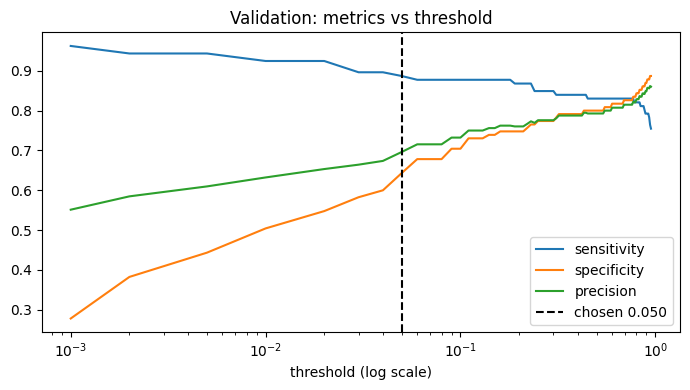


TEST SET PERFORMANCE at threshold 0.050 (vit_s_full)
metric         value   95% CI (patient bootstrap)
sensitivity    0.953   [0.904, 0.992]
specificity    0.792   [0.711, 0.868]
precision      0.818   [0.738, 0.885]
f1             0.880   [0.827, 0.922]
roc_auc        0.939   [0.902, 0.970]
pr_auc         0.926   [0.860, 0.970]

Confusion matrix  TP 121  FN 6  FP 27  TN 103
Malignant lesions in test set: 127 | missed: 6

For reference, default threshold 0.50: sensitivity 0.835, specificity 0.877, missed 21


In [17]:
TARGET_SENSITIVITY = 0.95
THRESHOLD_FLOOR = 0.05
N_BOOT = 1000

main_dir = os.path.join(OUT_DIR, MAIN_EXPERIMENT)
val_d = np.load(os.path.join(main_dir, "val_preds.npz"))
test_d = np.load(os.path.join(main_dir, "test_preds.npz"))
val_probs, val_labels = val_d["probs"], val_d["labels"]
test_probs, test_labels = test_d["probs"], test_d["labels"]

low_grid = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.04])
thresholds = np.unique(np.round(np.concatenate([low_grid, np.arange(0.05, 0.951, 0.01)]), 3))
display_ts = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


def stats_at(labels, probs, t):
    pred = probs >= t
    tp = int((pred & (labels == 1)).sum())
    fn = int((~pred & (labels == 1)).sum())
    fp = int((pred & (labels == 0)).sum())
    tn = int((~pred & (labels == 0)).sum())
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * prec * sens / (prec + sens) if prec + sens else 0.0
    return {
        "threshold": float(t), "sensitivity": sens, "specificity": spec, "precision": prec,
        "f1": f1, "flagged": (tp + fp) / len(labels), "tp": tp, "fp": fp, "tn": tn, "fn": fn,
    }


val_sweep = pd.DataFrame([stats_at(val_labels, val_probs, t) for t in thresholds])

eligible = val_sweep[val_sweep["sensitivity"] >= TARGET_SENSITIVITY]
target_t = float(eligible["threshold"].max()) if len(eligible) else None

if target_t is not None and target_t >= THRESHOLD_FLOOR:
    chosen_t = target_t
    reason = f"validation sensitivity >= {TARGET_SENSITIVITY:.0%} reached at {target_t:.3f}"
else:
    chosen_t = THRESHOLD_FLOOR
    if target_t is None:
        reason = f"no threshold reached {TARGET_SENSITIVITY:.0%} validation sensitivity, fell back to the floor {THRESHOLD_FLOOR}"
    else:
        reason = f"{TARGET_SENSITIVITY:.0%} validation sensitivity is only reached at {target_t:.3f}, below the floor, fell back to {THRESHOLD_FLOOR}"

print(f"Validation sweep for {MAIN_EXPERIMENT}:")
every = val_sweep["threshold"].isin(display_ts)
print(val_sweep[every][["threshold", "sensitivity", "specificity", "precision", "f1", "flagged", "fn", "fp"]].round(3).to_string(index=False))
print(f"\nRule: highest threshold with validation sensitivity >= {TARGET_SENSITIVITY:.0%}, never below {THRESHOLD_FLOOR}")
print(f"Outcome: {reason}")
print(f"Chosen threshold: {chosen_t:.3f}")
print(val_sweep[val_sweep["threshold"] == chosen_t][["sensitivity", "specificity", "precision", "f1", "flagged"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(val_sweep["threshold"], val_sweep["sensitivity"], label="sensitivity")
ax.plot(val_sweep["threshold"], val_sweep["specificity"], label="specificity")
ax.plot(val_sweep["threshold"], val_sweep["precision"], label="precision")
ax.axvline(chosen_t, color="k", linestyle="--", label=f"chosen {chosen_t:.3f}")
ax.set_xscale("log")
ax.set_xlabel("threshold (log scale)")
ax.set_title("Validation: metrics vs threshold")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "threshold_sweep.png"), dpi=120)
plt.show()

test_stats = stats_at(test_labels, test_probs, chosen_t)
test_stats["roc_auc"] = float(roc_auc_score(test_labels, test_probs))
test_stats["pr_auc"] = float(average_precision_score(test_labels, test_probs))

pids = test_df["patient_id"].values
assert len(pids) == len(test_labels)
groups = {p: np.where(pids == p)[0] for p in np.unique(pids)}
keys = list(groups)
rng = np.random.default_rng(SEED)
metric_names = ["sensitivity", "specificity", "precision", "f1", "roc_auc", "pr_auc"]
boot = []
for _ in range(N_BOOT):
    pick = rng.choice(len(keys), len(keys), replace=True)
    idx = np.concatenate([groups[keys[k]] for k in pick])
    l, p = test_labels[idx], test_probs[idx]
    s = stats_at(l, p, chosen_t)
    boot.append([s["sensitivity"], s["specificity"], s["precision"], s["f1"], roc_auc_score(l, p), average_precision_score(l, p)])
lo, hi = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
test_ci = {m: (float(lo[i]), float(hi[i])) for i, m in enumerate(metric_names)}

print(f"\nTEST SET PERFORMANCE at threshold {chosen_t:.3f} ({MAIN_EXPERIMENT})")
print(f"{'metric':<12}{'value':>8}   95% CI (patient bootstrap)")
for m in metric_names:
    print(f"{m:<12}{test_stats[m]:>8.3f}   [{test_ci[m][0]:.3f}, {test_ci[m][1]:.3f}]")
print(f"\nConfusion matrix  TP {test_stats['tp']}  FN {test_stats['fn']}  FP {test_stats['fp']}  TN {test_stats['tn']}")
print(f"Malignant lesions in test set: {int(test_labels.sum())} | missed: {test_stats['fn']}")

default_stats = stats_at(test_labels, test_probs, 0.5)
print(f"\nFor reference, default threshold 0.50: sensitivity {default_stats['sensitivity']:.3f}, specificity {default_stats['specificity']:.3f}, missed {default_stats['fn']}")

with open(os.path.join(OUT_DIR, "final_test_report.json"), "w") as f:
    json.dump({"experiment": MAIN_EXPERIMENT, "threshold": chosen_t, "target_sensitivity": TARGET_SENSITIVITY, "test": test_stats, "test_ci": test_ci}, f, indent=2)


## **Impact estimation**

In [18]:
POPULATION = 1000
PREVALENCE = 0.05

cancers = POPULATION * PREVALENCE
healthy = POPULATION - cancers

sens, spec = test_stats["sensitivity"], test_stats["specificity"]
sens_lo, sens_hi = test_ci["sensitivity"]
spec_lo, spec_hi = test_ci["specificity"]

caught = sens * cancers
missed = (1 - sens) * cancers
false_referrals = (1 - spec) * healthy
referrals = caught + false_referrals

print(f"Screening {POPULATION} people, {PREVALENCE:.0%} with a malignant lesion ({cancers:.0f} cancers, {healthy:.0f} healthy)")
print(f"Threshold {chosen_t:.2f} | test sensitivity {sens:.3f} | test specificity {spec:.3f}")
print(f"Cancers caught:        {caught:.0f}")
print(f"Cancers missed:        {missed:.0f}  (range {(1 - sens_hi) * cancers:.0f} to {(1 - sens_lo) * cancers:.0f})")
print(f"Unnecessary referrals: {false_referrals:.0f}  (range {(1 - spec_hi) * healthy:.0f} to {(1 - spec_lo) * healthy:.0f})")
print(f"Total referrals:       {referrals:.0f}  ({referrals / POPULATION:.1%} of people)")
print(f"Share of referrals that are real cancers: {caught / referrals:.1%}")


Screening 1000 people, 5% with a malignant lesion (50 cancers, 950 healthy)
Threshold 0.05 | test sensitivity 0.953 | test specificity 0.792
Cancers caught:        48
Cancers missed:        2  (range 0 to 5)
Unnecessary referrals: 197  (range 126 to 274)
Total referrals:       245  (24.5% of people)
Share of referrals that are real cancers: 19.4%


# **Running all the experiments and getting the ablation table**
You need to set RUN_ABLATIONS = True in the config to run these cells successfully and regenerate the results

In [11]:
all_results = {}
for name in RUN_LIST:
    all_results[name] = run_experiment(name, EXPERIMENTS[name])

for name, r in all_results.items():
    print(
        f"{name}: best epoch {r['best_epoch']} | trained {r['train_minutes']:.1f} min | "
        f"val PR-AUC {r['val']['pr_auc']:.3f} | val ROC-AUC {r['val']['roc_auc']:.3f}"
    )


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 156MB/s]


[r50_linear_probe] 01/20 |  26.9s | train_loss 0.7328 | val_loss 0.7216 | P 0.556 R 0.745 S 0.452 F1 0.637 | ROC 0.685 PR 0.686  <- best
[r50_linear_probe] 02/20 |  25.2s | train_loss 0.7053 | val_loss 0.6803 | P 0.700 R 0.726 S 0.713 F1 0.713 | ROC 0.773 PR 0.762  <- best
[r50_linear_probe] 03/20 |  25.1s | train_loss 0.6593 | val_loss 0.6387 | P 0.689 R 0.774 S 0.678 F1 0.729 | ROC 0.784 PR 0.757
[r50_linear_probe] 04/20 |  23.9s | train_loss 0.6222 | val_loss 0.6181 | P 0.750 R 0.566 S 0.826 F1 0.645 | ROC 0.788 PR 0.762
[r50_linear_probe] 05/20 |  25.3s | train_loss 0.6101 | val_loss 0.6019 | P 0.728 R 0.708 S 0.757 F1 0.718 | ROC 0.799 PR 0.767  <- best
[r50_linear_probe] 06/20 |  25.9s | train_loss 0.5888 | val_loss 0.5949 | P 0.784 R 0.651 S 0.835 F1 0.711 | ROC 0.804 PR 0.771  <- best
[r50_linear_probe] 07/20 |  25.2s | train_loss 0.5831 | val_loss 0.5870 | P 0.721 R 0.755 S 0.730 F1 0.737 | ROC 0.810 PR 0.777  <- best
[r50_linear_probe] 08/20 |  24.6s | train_loss 0.5739 | val

/tmp/ipykernel_646/1355271785.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[vit_s_partial] 01/20 |  29.5s | train_loss 0.7728 | val_loss 0.6423 | P 0.731 R 0.538 S 0.817 F1 0.620 | ROC 0.747 PR 0.763  <- best
[vit_s_partial] 02/20 |  29.1s | train_loss 0.5646 | val_loss 0.5405 | P 0.752 R 0.745 S 0.774 F1 0.749 | ROC 0.827 PR 0.823  <- best
[vit_s_partial] 03/20 |  29.3s | train_loss 0.4516 | val_loss 0.5484 | P 0.768 R 0.689 S 0.809 F1 0.726 | ROC 0.839 PR 0.831  <- best
[vit_s_partial] 04/20 |  28.9s | train_loss 0.4001 | val_loss 0.6748 | P 0.780 R 0.604 S 0.843 F1 0.681 | ROC 0.840 PR 0.833  <- best
[vit_s_partial] 05/20 |  28.9s | train_loss 0.3463 | val_loss 0.5140 | P 0.754 R 0.811 S 0.757 F1 0.782 | ROC 0.866 PR 0.851  <- best
[vit_s_partial] 06/20 |  28.8s | train_loss 0.2816 | val_loss 0.6371 | P 0.819 R 0.726 S 0.852 F1 0.770 | ROC 0.846 PR 0.824
[vit_s_partial] 07/20 |  28.8s | train_loss 0.2389 | val_loss 0.7652 | P 0.836 R 0.575 S 0.896 F1 0.682 | ROC 0.859 PR 0.822
[vit_s_partial] 08/20 |  28.9s | train_loss 0.2254 | val_loss 0.5936 | P 0.790 R

experiment       r50_linear_probe  r50_partial  r50_full  vit_s_full  \
trainable_M                 0.000       23.280    23.510      21.980   
best_epoch                 20.000        8.000    12.000      13.000   
minutes                     8.300       10.200    11.700      14.000   
val_pr_auc                  0.789        0.866     0.868       0.890   
val_roc_auc                 0.827        0.870     0.855       0.880   
test_pr_auc                 0.806        0.894     0.891       0.926   
test_roc_auc                0.844        0.904     0.913       0.939   
test_recall@0.5             0.654        0.843     0.819       0.835   
test_spec@0.5               0.831        0.792     0.838       0.877   

experiment       vit_s_partial  
trainable_M             10.650  
best_epoch               5.000  
minutes                  9.900  
val_pr_auc               0.851  
val_roc_auc              0.866  
test_pr_auc              0.939  
test_roc_auc             0.948  
test_recall@0.5

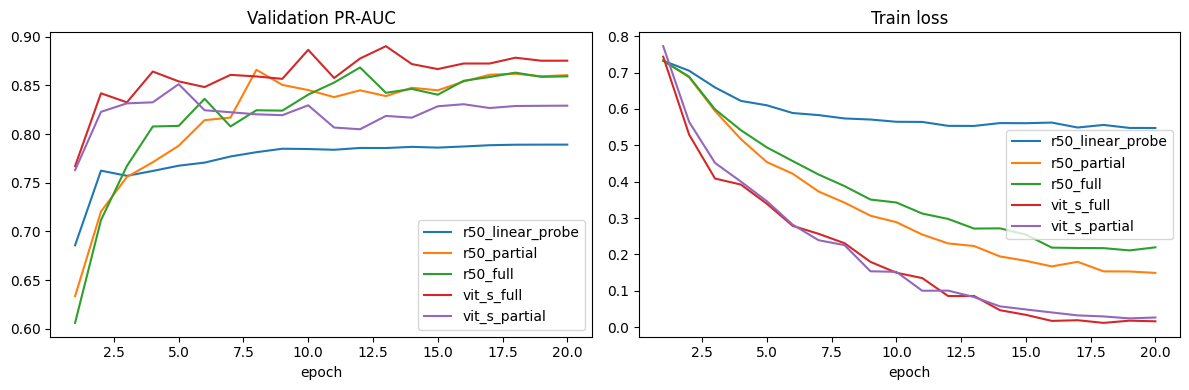

In [12]:
rows = []
curves = {}
for name in EXPERIMENTS:
    rp = os.path.join(OUT_DIR, name, "results.json")
    hp = os.path.join(OUT_DIR, name, "history.csv")
    if not os.path.exists(rp):
        continue
    with open(rp) as f:
        r = json.load(f)
    rows.append({
        "experiment": name,
        "trainable_M": round(r["trainable_params_m"], 2),
        "best_epoch": r["best_epoch"],
        "minutes": round(r["train_minutes"], 1),
        "val_pr_auc": r["val"]["pr_auc"],
        "val_roc_auc": r["val"]["roc_auc"],
        "test_pr_auc": r["test"]["pr_auc"],
        "test_roc_auc": r["test"]["roc_auc"],
        "test_recall@0.5": r["test"]["recall"],
        "test_spec@0.5": r["test"]["specificity"],
    })
    if os.path.exists(hp):
        curves[name] = pd.read_csv(hp)

if len(rows) < 2:
    print("Only one experiment has been run. Set RUN_ABLATIONS = True in the config cell and rerun from there to compare freezing strategies.")
else:
    comparison = pd.DataFrame(rows).set_index("experiment").round(3)
    comparison.to_csv(os.path.join(OUT_DIR, "comparison.csv"))
    print(comparison.T)
    print(f"\nBest by validation {MONITOR}: {comparison['val_pr_auc'].idxmax()}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in curves.items():
        axes[0].plot(h["epoch"], h["val_pr_auc"], label=name)
        axes[1].plot(h["epoch"], h["train_loss"], label=name)
    axes[0].set_title("Validation PR-AUC")
    axes[1].set_title("Train loss")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "comparison.png"), dpi=120)
    plt.show()
